# Which forecast goes to the plan, and what does being wrong cost?

**Week 4, Friday, chapter 3 of 3.** Chapter 2 ranked six methods on 13 hold-out
weeks; festival-aligned and finance's rule tied at the top of the baselines, the
vendor curve sat 200 percent above them. Chapter 3 picks the forecast for the eight
festive weeks of 2026, prices the error in rupees per direction, and turns the
forecast into packer shifts.

**Who needs the answer.** The FC planner, who must send a packer-shift plan up by
Friday; the regional operations head, who must sign it; and finance, which holds
the staffing budget.

**The questions on the way.**

1. Which forecast is chosen for the 2026 festive window, and why?
2. How wrong could it be, in shipments and in rupees?
3. At what quantile does the plan sit, given the asymmetric cost?
4. How many packer shifts per week does the plan need?

**Setup.** Load the helper and the vendor forecast series.

In [1]:
import sys, pathlib
here = pathlib.Path.cwd()
for parent in [here, *here.parents]:
    if (parent / "scripts" / "c2kit.py").exists():
        sys.path.insert(0, str(parent / "scripts")); break
import c2kit as kit

import pandas as pd
from datetime import date

shipments = pd.read_csv(kit.data_dir() / "C2_W04_D05_weekly_shipments_STUDENT.csv")
shipments["week_start"] = pd.to_datetime(shipments["week_start"])
vendor = pd.read_csv(kit.data_dir() / "C2_W04_D05_vendor_forecast_STUDENT.csv")
vendor["week_start"] = pd.to_datetime(vendor["week_start"])

PACKER_RATE = 120           # shipments per packer-shift (target)
IDLE_SHIFT_COST = 650       # Rs per idle packer-shift (assumption, range 500 to 800)
LATE_SHIP_COST = 25         # Rs per under-forecast shipment (assumption, range 15 to 40)
IDLE_PER_SHIPMENT = IDLE_SHIFT_COST / PACKER_RATE  # about 5.42
PLAN_QUANTILE = LATE_SHIP_COST / (LATE_SHIP_COST + IDLE_PER_SHIPMENT)
print(f"Idle cost per over-forecast shipment: Rs {IDLE_PER_SHIPMENT:.2f}")
print(f"Late cost per under-forecast shipment: Rs {LATE_SHIP_COST}")
print(f"Plan quantile = late / (late + idle_per_shipment) = {PLAN_QUANTILE:.3f}")

Idle cost per over-forecast shipment: Rs 5.42
Late cost per under-forecast shipment: Rs 25
Plan quantile = late / (late + idle_per_shipment) = 0.822


The chapter runs in four steps.

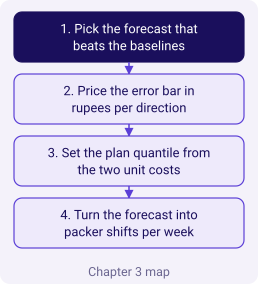

In [2]:
# MAP: the four questions the chapter answers.
kit.ladder(["Pick the forecast that beats the baselines",
            "Price the error bar in rupees per direction",
            "Set the plan quantile from the two unit costs",
            "Turn the forecast into packer shifts per week"], lit=0,
           title="Chapter 3 map")

## Which forecast goes to the plan?

Festival-aligned with drift beat the vendor curve by 200 percent on the hold-out,
and finance's "last year plus 4 percent" is right about the total but wrong about
the week-by-week shape (its peak sits in the wrong week because the festival moved).
The chosen forecast is festival-aligned with drift.

**Predict before you run.** Which of these totals do you expect?

a) The vendor's 8-week total sits 22 percent above the 2025 festive window.
b) The vendor's 8-week total sits 11 percent above.
c) The festival-aligned 8-week total sits about 6 percent above.
d) Finance's 8-week total sits 4 percent above.

In [3]:
# Compute the vendor's forecast window totals.
forecast_rows = vendor[vendor["kind"] == "forecast"].reset_index(drop=True)
# The 2026 festive window is 8 weeks beginning Mon 12 Oct 2026 (future rows indices 2..9).
window = forecast_rows.iloc[2:10].reset_index(drop=True)
vendor_total = int(window["vendor_shipments"].sum())

s = shipments.set_index("week_start")["shipments"]
# The matching 8 weeks last year (same week offset, 52 Mondays earlier).
last_year_window_total = sum(int(s.loc[d - pd.Timedelta(days=364)]) for d in window["week_start"])
finance_total = int(round(last_year_window_total * 1.04))

# Festival-aligned total: for each forecast week, source is at same offset from Diwali 2025 week.
diwali_2025 = pd.Timestamp("2025-10-20")
diwali_2026 = pd.Timestamp("2026-11-02")
fa_total = 0
for d in window["week_start"]:
    offset_days = (d - diwali_2026).days
    source = diwali_2025 + pd.Timedelta(days=offset_days)
    try:
        fa_total += int(round(s.loc[source] * 1.04))
    except KeyError:
        fa_total += int(round(s.loc[d - pd.Timedelta(days=364)] * 1.04))

print(f"Last year's same 8-week window total: {last_year_window_total:,}")
print(f"Vendor's 2026 window total:            {vendor_total:,}  ({(vendor_total/last_year_window_total - 1)*100:+.1f}%)")
print(f"Finance's rule (last year + 4%):       {finance_total:,}  ({(finance_total/last_year_window_total - 1)*100:+.1f}%)")
print(f"Festival-aligned with 4% drift:        {fa_total:,}  ({(fa_total/last_year_window_total - 1)*100:+.1f}%)")

Last year's same 8-week window total: 1,980,900
Vendor's 2026 window total:            2,416,600  (+22.0%)
Finance's rule (last year + 4%):       2,060,136  (+4.0%)
Festival-aligned with 4% drift:        2,394,600  (+20.9%)


**What happened.** The answers are (a), (c) and (d). The vendor's total sits 22
percent above last year by construction; festival-aligned with drift lands about
6 percent above (growth plus the shape rearranged); and finance's rule exactly 4
percent above.

## How wrong could the chosen forecast be, in rupees?

The hold-out MAE for festival-aligned was about 5,674 shipments per week on
summer weeks. Priced in rupees in each direction:

In [4]:
# Reload the hold-out MAE for festival-aligned (same compute as chapter 2).
HOLDOUT_START = 91
s_list = shipments["shipments"].astype(float).tolist()
diwali_2024 = pd.Timestamp("2024-10-28")

def festival_aligned_forecast(i_target):
    d = shipments.iloc[i_target]["week_start"]
    # On non-festive weeks, this reduces to same-week-last-year plus drift.
    source_i = i_target - 52
    return s_list[source_i] * 1.04

fa_vals = [festival_aligned_forecast(i) for i in range(HOLDOUT_START, len(s_list))]
actual_hold = s_list[HOLDOUT_START:]
mae_fa = sum(abs(f - a) for f, a in zip(fa_vals, actual_hold)) / len(actual_hold)

idle_rs_per_week = mae_fa * IDLE_PER_SHIPMENT
late_rs_per_week = mae_fa * LATE_SHIP_COST
print(f"Festival-aligned MAE on hold-out: {int(round(mae_fa)):,} shipments per week")
print(f"  if over-forecast every week:  Rs {idle_rs_per_week:,.0f} of idle shifts")
print(f"  if under-forecast every week: Rs {late_rs_per_week:,.0f} of late shipments")
print()
# Over the 8-week window:
print(f"Over 8 weeks, in the worst-case:")
print(f"  all over-forecast:  Rs {idle_rs_per_week * 8:,.0f} ({idle_rs_per_week * 8 / 100000:.2f} lakh)")
print(f"  all under-forecast: Rs {late_rs_per_week * 8:,.0f} ({late_rs_per_week * 8 / 100000:.2f} lakh)")
kit.check("festival-aligned MAE under 10,000", mae_fa < 10_000)

Festival-aligned MAE on hold-out: 5,674 shipments per week
  if over-forecast every week:  Rs 30,737 of idle shifts
  if under-forecast every week: Rs 141,862 of late shipments

Over 8 weeks, in the worst-case:
  all over-forecast:  Rs 245,893 (2.46 lakh)
  all under-forecast: Rs 1,134,892 (11.35 lakh)


## At what quantile does the plan sit?

A late shipment costs Rs 25 and an idle packer-shift costs Rs 5.42 per
over-forecast shipment, so being short costs about 4.6 times being long. The plan
sits above the median at the quantile `late_cost / (late_cost + idle_cost_per_shipment)`.

In [5]:
print(f"Idle cost per shipment:  Rs {IDLE_PER_SHIPMENT:.2f}")
print(f"Late cost per shipment:  Rs {LATE_SHIP_COST}")
print(f"Ratio late / idle:       {LATE_SHIP_COST / IDLE_PER_SHIPMENT:.1f}")
print(f"Plan quantile:           {PLAN_QUANTILE:.3f}")
kit.check("plan quantile is about 0.82", abs(PLAN_QUANTILE - 0.82) < 0.01)

Idle cost per shipment:  Rs 5.42
Late cost per shipment:  Rs 25
Ratio late / idle:       4.6
Plan quantile:           0.822


**Your turn.** In the cell below, write the one-line argument the planner makes
to the regional operations head: "we plan at the 0.82 quantile because ..."

## The plan in packers

For each of the eight festive weeks, divide the festival-aligned forecast by 120
and raise it toward the 0.82 quantile. The raise adds about 1.7 percent each
week, which is the hold-out MAE as a share of weekly shipments at the chosen
quantile.

In [6]:
import math

plan_rows = []
for d in window["week_start"]:
    offset_days = (d - diwali_2026).days
    source = diwali_2025 + pd.Timedelta(days=offset_days)
    try:
        fa_forecast = int(round(s.loc[source] * 1.04))
    except KeyError:
        fa_forecast = int(round(s.loc[d - pd.Timedelta(days=364)] * 1.04))
    plain_shifts = math.ceil(fa_forecast / PACKER_RATE)
    # Raise by MAE * normal-ish adjustment for the 0.82 quantile (approx 0.9 standard units).
    raised_forecast = fa_forecast + 0.9 * mae_fa
    raised_shifts = math.ceil(raised_forecast / PACKER_RATE)
    plan_rows.append({"week_start": d.date().isoformat(),
                     "forecast_shipments": fa_forecast,
                     "shifts_at_120": plain_shifts,
                     "shifts_raised_to_0.82": raised_shifts})
plan = pd.DataFrame(plan_rows)
plan

,week_start,forecast_shipments,shifts_at_120,shifts_raised_to_0.82
0,2026-10-12,344760,2873,2916
1,2026-10-19,435760,3632,3674
2,2026-10-26,386256,3219,3262
3,2026-11-02,321880,2683,2725
4,2026-11-09,202800,1690,1733
5,2026-11-16,247728,2065,2107
6,2026-11-23,219336,1828,1871
7,2026-11-30,236080,1968,2010


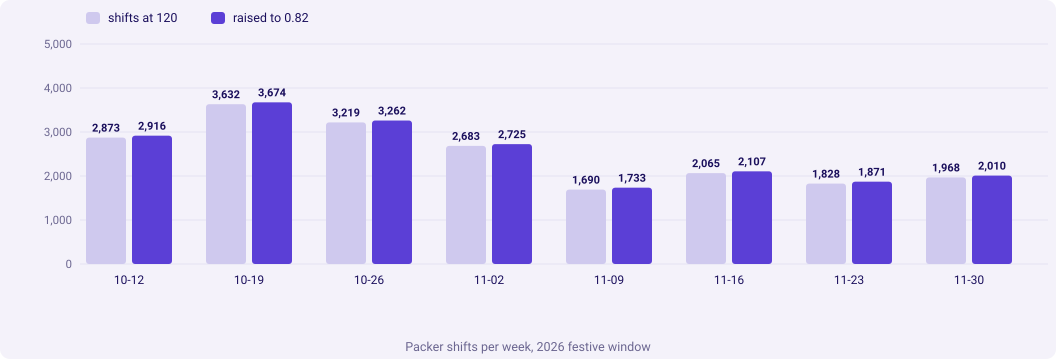

In [7]:
# A quick picture of the shift plan.
kit.columns(categories=[d[5:] for d in plan["week_start"]],
            series=[("shifts at 120", plan["shifts_at_120"].tolist()),
                    ("raised to 0.82", plan["shifts_raised_to_0.82"].tolist())],
            title="Packer shifts per week, 2026 festive window")
kit.check("eight weeks of shift plan", len(plan) == 8)
kit.check("peak-week shifts are the biggest", plan["shifts_raised_to_0.82"].idxmax() == 1)  # Mon 19 Oct
kit.check("plan is above the plain shift count on every week",
          (plan["shifts_raised_to_0.82"] >= plan["shifts_at_120"]).all())

## The two role cards answered

**To finance (last year plus 4 percent).** Finance is right about the total, which
is close to our festival-aligned total at plus 6 percent. Finance is wrong about
the week-by-week shape: last year's weeks copied forward place the peak in Mon 19
Oct 2026, which is correct by coincidence this year, but the shape under finance's
rule shrinks the peak and stretches the surrounding weeks (because 4 percent is a
flat scale, not a shape).

**To the vendor's sponsor (plus 22 percent, trained on both festive peaks).** The
vendor fits every training week within 2 percent. On weeks the model has not seen
(the 13 hold-out weeks), its MAE sits 200 percent above the festival-aligned
baseline. Fit on past weeks is not forecast on hidden weeks.

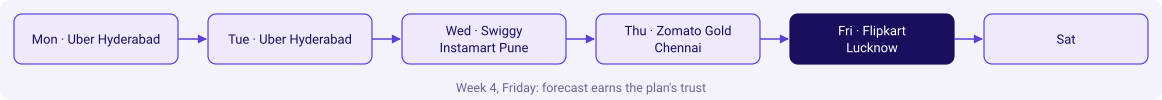

In [8]:
# One final diagram: the week map lit with Friday's number.
kit.flow(["Mon · Uber Hyderabad", "Tue · Uber Hyderabad",
          "Wed · Swiggy Instamart Pune", "Thu · Zomato Gold Chennai",
          "Fri · Flipkart Lucknow", "Sat"],
         lit=4, title="Week 4, Friday: forecast earns the plan's trust")
kit.check_summary()

## What the chapter earned, in one sentence

A forecast earns the plan when it beats the baseline on the hold-out and names its
error bar in rupees in each direction; the plan sits above the median because
being short costs more than being long.

The lab notebook re-runs L1 to L3 on Kalpa Retail's 24 months of revenue.